# Problem Statement

The objective of this project is to develop a machine learning model capable of classifying images into three predefined categories. The model will learn visual patterns from the provided image dataset and use these patterns to accurately assign each image to its corresponding class.

# Project Aim

The aim of this project is to build and evaluate an image classification model that can automatically classify images into the predefined three labels with good accuracy.

### IMPORT LIBRARIES AND DEFINE PATH

In [1]:
import os
import zipfile
from pathlib import Path

# Path of the ZIP file
zip_path = Path("Bin-dataset-3.zip")

# Folder where the dataset will be extracted
extract_path = Path("dataset")

print("ZIP exists:", zip_path.exists())
print("ZIP size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")

ZIP exists: True
ZIP size: 171.97 MB


### EXTRACT THE ZIP FILE

In [2]:
# Extract dataset
if not extract_path.exists():
    extract_path.mkdir()

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")

Dataset extracted successfully.


### DISPLAY EXTRACTED FOLDER STRUCTURE

In [3]:
# Display the extracted folder structure
for root, dirs, files in os.walk(extract_path):
    level = root.replace(str(extract_path), "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")
    
    for file in files[:10]:
        print(f"{indent}    {file}")

dataset/
    Data/
        .ipynb_checkpoints/
        test/
            angular_leaf_spot/
                angular_leaf_spot_test.0.jpg
                angular_leaf_spot_test.1.jpg
                angular_leaf_spot_test.10.jpg
                angular_leaf_spot_test.11.jpg
                angular_leaf_spot_test.12.jpg
                angular_leaf_spot_test.13.jpg
                angular_leaf_spot_test.14.jpg
                angular_leaf_spot_test.15.jpg
                angular_leaf_spot_test.16.jpg
                angular_leaf_spot_test.17.jpg
            bean_rust/
                bean_rust_test.0.jpg
                bean_rust_test.1.jpg
                bean_rust_test.10.jpg
                bean_rust_test.11.jpg
                bean_rust_test.12.jpg
                bean_rust_test.13.jpg
                bean_rust_test.14.jpg
                bean_rust_test.15.jpg
                bean_rust_test.16.jpg
                bean_rust_test.17.jpg
            healthy/
                healthy_test

```text
Data/
├── train/
├── validation/
└── test/
```

Dataset is already divided into train, test and validation sets.

Moreover it has exact 3 Classes :-

1.angular_leaf_spot
2.bean_rust 
3.healthy

```text
FOLDER STRUCTURE - dataset/
└── Data/
    ├── train/
    │   ├── angular_leaf_spot/
    │   ├── bean_rust/
    │   └── healthy/
    ├── validation/
    │   ├── angular_leaf_spot/
    │   ├── bean_rust/
    │   └── healthy/
    └── test/
        ├── angular_leaf_spot/
        ├── bean_rust/
        └── healthy/
```

### DEFINE DATASET PATHS

In [4]:
from pathlib import Path

data_path = Path("dataset/Data")

train_path = data_path / "train"
val_path = data_path / "validation"
test_path = data_path / "test"

print("Train path:", train_path)
print("Validation path:", val_path)
print("Test path:", test_path)

Train path: dataset\Data\train
Validation path: dataset\Data\validation
Test path: dataset\Data\test


### CHECK THE 3 CLASSES

In [5]:
classes = sorted([
    folder.name 
    for folder in train_path.iterdir() 
    if folder.is_dir()
])

print("Classes:", classes)
print("Number of classes:", len(classes))

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
Number of classes: 3


### COUNT IMAGE IN EACH CLASS

In [6]:
for split_name, split_path in [
    ("Train", train_path),
    ("Validation", val_path),
    ("Test", test_path)
]:

    print(f"\n{split_name} dataset:")

    for class_name in classes:
        class_path = split_path / class_name
        count = len(list(class_path.iterdir()))
        print(f"{class_name}: {count}")


Train dataset:
angular_leaf_spot: 345
bean_rust: 348
healthy: 342

Validation dataset:
angular_leaf_spot: 44
bean_rust: 45
healthy: 44

Test dataset:
angular_leaf_spot: 43
bean_rust: 43
healthy: 42


The Dataset is very balanced. No need for SMOTE or class-weight balancing. Also no need to create another split

| Split | Angular leaf spot | Bean rust | Healthy | Total |
|---|---:|---:|---:|---:|
| Train | 345 | 348 | 342 | **1,035** |
| Validation | 44 | 45 | 44 | **133** |
| Test | 43 | 43 | 42 | **128** |

### CHECK IMAGE DIMENSIONS

In [7]:
from PIL import Image

for class_name in classes:
    
    class_path = train_path / class_name
    
    first_image = next(
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )
    
    with Image.open(first_image) as img:
        print(f"{class_name}: {img.size}, {img.mode}")

angular_leaf_spot: (500, 500), RGB
bean_rust: (500, 500), RGB
healthy: (500, 500), RGB


### DISPLAY SAMPLE IMAGES

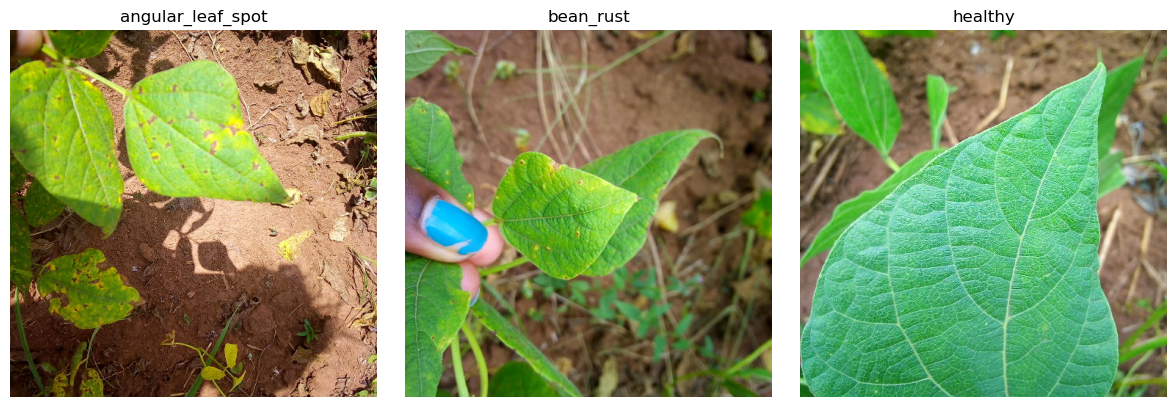

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, class_name in zip(axes, classes):
    
    class_path = train_path / class_name
    
    image_file = next(
        file for file in class_path.iterdir()
        if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )
    
    image = Image.open(image_file)
    
    ax.imshow(image)
    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Key Preprocessing & Modeling Insights

* **Dataset Profile:** Original images are **500×500 RGB**, providing a solid foundation for preprocessing.
* **Modeling Strategy:** Because the dataset is small (**1,296 images**), we will use **Transfer Learning** instead of training a CNN from scratch. This approach is faster, requires less data, and yields higher accuracy.
* **Target Resolution:** Images will be resized to **224×224** to match the standard input requirements for pre-trained architectures like **MobileNetV2**.
* **Regularisation Strategy:** We will apply **Data Augmentation** to the training set. This forces the model to learn from varied orientations, reducing overfitting and boosting generalization.



### IMPORT TENSORFLOW

In [9]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### DEFINE IMAGE PARAMETERS

In [10]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 3

### Insight

Images are resized to **224×224 pixels** for consistent model input, a batch size of **32** is used for efficient training, and the model is configured for **3 output classes**.

### TRAINING DATA GENERATOR

In [11]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.20,
    horizontal_flip=True
)

### Insight

Training images are rescaled to **0–1** and augmented using rotation, shifting, zooming, and horizontal flipping to increase image variability and improve **model generalization**.

### VALIDATION AND TEST GENERATORS

In [12]:
val_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

### Insight

Validation and test images are only **rescaled to 0–1** without augmentation, ensuring consistent and unbiased evaluation of the trained model.

### LOAD THE DATASETS

In [13]:
train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    val_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 1034 images belonging to 3 classes.
Found 133 images belonging to 3 classes.
Found 128 images belonging to 3 classes.


### Insight

The dataset contains **1,034 training images, 133 validation images, and 128 test images** across **3 classes**. Training data is shuffled to improve learning, while validation and test data remain unshuffled for consistent evaluation.

Three separate image generators are created for the **training, validation, and test datasets** using `flow_from_directory()`.

- **Training generator:** Loads images from the training directory, resizes them to **224×224 pixels**, groups them into batches of **32**, and uses **categorical labels** for the three-class classification problem. `shuffle=True` randomly changes the order of training images in each epoch, helping the model learn without depending on the original image order.

- **Validation generator:** Processes validation images using the same image size and batch size. `shuffle=False` keeps the image order fixed, making validation results consistent and easier to evaluate.

- **Test generator:** Processes the completely unseen test images using the same preprocessing settings. `shuffle=False` is important because the predictions can then be matched correctly with the original class labels during evaluation and confusion-matrix analysis.

Overall, these generators provide the model with images in a **consistent format while maintaining separate and controlled data pipelines for training, validation, and final testing**.

### CHECK CLASS MAPPING

In [14]:
print("Class mapping:")
print(train_generator.class_indices)

Class mapping:
{'angular_leaf_spot': 0, 'bean_rust': 1, 'healthy': 2}


### BUILD THE MODEL

In [15]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Add our classification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.5)(x)

output = Dense(NUM_CLASSES, activation="softmax")(x)

# Create final model
model = Model(inputs=base_model.input, outputs=output)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,422,339 (9.24 MB)

 Trainable params: 164,355 (642.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Insight

A pretrained **MobileNetV2** model is used as the base of the image classification system. The model has been trained on the **ImageNet dataset**, allowing it to provide useful visual features such as edges, textures, shapes, and patterns without training the entire network from scratch.

The pretrained layers are **frozen** using `base_model.trainable = False`, so their learned weights are not updated during training. This reduces training time and helps prevent overfitting, especially because the bean leaf dataset is relatively small.

A **Global Average Pooling** layer converts the feature maps produced by MobileNetV2 into a compact feature representation. A **Dense layer with 128 neurons** then learns task-specific patterns relevant to bean leaf classification.

A **Dropout rate of 0.5** is applied to randomly deactivate neurons during training, which helps reduce over-reliance on specific features and improves model generalization.

Finally, a **Softmax output layer with 3 neurons** is used because the dataset contains three classes: **Angular Leaf Spot, Bean Rust, and Healthy**. The output provides the probability of an image belonging to each class.

### COMPILE THE MODEL

In [16]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

### Insight

The model is compiled using the **Adam optimizer**, **categorical cross-entropy loss**, and **accuracy** as the evaluation metric.

- **Adam Optimizer:** Adjusts the model's trainable weights during training by calculating how much each weight contributes to the prediction error. Adam is widely used because it provides adaptive learning rates and generally converges efficiently.

- **Categorical Cross-Entropy:** Measures the difference between the actual class label and the probability distribution predicted by the model. Since this is a **3-class classification problem** with one-hot encoded labels (`class_mode="categorical"`), categorical cross-entropy is appropriate.

- **Accuracy:** Measures the percentage of images that are correctly classified out of all images evaluated.

Overall, these settings define **how the model learns, how prediction errors are measured, and how classification performance is monitored during training**.

### EARLY STOPPING

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

### Insight

An **EarlyStopping** callback is used to prevent the model from continuing training when its validation performance stops improving.

- **`monitor="val_loss"`:** The model's validation loss is monitored after each epoch. A decrease in validation loss indicates that the model is improving on unseen validation data.
- **`patience=3`:** Training is allowed to continue for up to **3 consecutive epochs** without improvement in validation loss. If no improvement occurs, training is stopped.
- **`restore_best_weights=True`:** After training stops, the model automatically restores the weights from the epoch that achieved the **lowest validation loss**, rather than keeping the weights from the final epoch.

This helps **reduce overfitting**, avoids unnecessary training, and ensures that the final model retains its **best validation performance**.

### TRAIN THE MODEL

In [18]:
EPOCHS = 20

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

Epoch 1/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.6315 - loss: 0.8192 - val_accuracy: 0.8496 - val_loss: 0.4186
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 29s 892ms/step - accuracy: 0.7921 - loss: 0.5224 - val_accuracy: 0.8571 - val_loss: 0.3607
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 31s 930ms/step - accuracy: 0.8356 - loss: 0.4213 - val_accuracy: 0.8872 - val_loss: 0.2865
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 29s 886ms/step - accuracy: 0.8569 - loss: 0.3821 - val_accuracy: 0.8797 - val_loss: 0.2611
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 29s 882ms/step - accuracy: 0.8472 - loss: 0.3631 - val_accuracy: 0.8947 - val_loss: 0.2960
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 907ms/step - accuracy: 0.8791 - loss: 0.3199 - val_accuracy: 0.8947 - val_loss: 0.2478
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 982ms/step - accuracy: 0.8627 - loss: 0.3249 - val_accuracy: 0.9023 - val_loss: 0.2745
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 30s 905ms/step - accuracy: 0.8820 - loss: 0.3074 - val_accurac

### Insight

The model was trained for a maximum of **20 epochs**, with **EarlyStopping** monitoring the validation loss to prevent unnecessary training and overfitting.

During training, both training and validation performance improved overall. The **best validation performance was achieved at Epoch 11**, where:

- **Training Accuracy:** 89.46%
- **Validation Accuracy:** 93.23%
- **Validation Loss:** 0.2211

After Epoch 11, the validation loss increased from **0.2211 to 0.3071** in Epoch 12 and remained higher in the following epochs. This indicates that the model had reached its best generalization point and further training was no longer improving validation performance.

Because `restore_best_weights=True` was used, the model will retain the weights from the epoch with the **lowest validation loss (Epoch 11)** when training stops.

The training results indicate that the model achieved strong validation performance while maintaining a relatively small difference between training and validation accuracy, suggesting **reduced overfitting and improved generalization**.

### TEST THE MODEL

In [26]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 522ms/step - accuracy: 0.9219 - loss: 0.2327
Test Loss: 0.23271965980529785
Test Accuracy: 0.921875


### Insight

The final model was evaluated on the **completely unseen test dataset** containing **128 images**.

The model achieved:

- **Test Accuracy:** 92.19%
- **Test Loss:** 0.2327

A test accuracy of **92.19%** indicates that the model correctly classified approximately **92 out of every 100 test images**.

The test results confirm that the trained MobileNetV2 model generalizes well to unseen bean leaf images and successfully performs the required **three-class classification task**.

### CONFUSION MATRIX

In [27]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Generate predictions
predictions = model.predict(test_generator)

# Convert probabilities to class labels
y_pred = np.argmax(predictions, axis=1)

# Actual labels
y_true = test_generator.classes

# Class names
class_names = list(test_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 527ms/step
Confusion Matrix:
[[41  2  0]
 [ 6 36  1]
 [ 0  1 41]]

Classification Report:
                   precision    recall  f1-score   support

angular_leaf_spot       0.87      0.95      0.91        43
        bean_rust       0.92      0.84      0.88        43
          healthy       0.98      0.98      0.98        42

         accuracy                           0.92       128
        macro avg       0.92      0.92      0.92       128
     weighted avg       0.92      0.92      0.92       128



### Insight

The **confusion matrix** and **classification report** provide a detailed evaluation of the model's performance across the three bean leaf classes.

The confusion matrix shows that:

- **Angular Leaf Spot:** 41 out of 43 images were correctly classified, with 2 misclassified as Bean Rust.
- **Bean Rust:** 36 out of 43 images were correctly classified, while 6 were predicted as Angular Leaf Spot and 1 as Healthy.
- **Healthy:** 41 out of 42 images were correctly classified, with only 1 misclassified as Bean Rust.

From the classification report:

- **Healthy** achieved the best performance with an **F1-score of 0.98**, indicating highly accurate identification of healthy leaves.
- **Angular Leaf Spot** achieved an **F1-score of 0.91** with a recall of **0.95**, meaning most actual Angular Leaf Spot images were correctly detected.
- **Bean Rust** achieved an **F1-score of 0.88**, making it the most challenging class for the model.
- The overall **accuracy, macro F1-score, and weighted F1-score are all 0.92**.

Overall, the model demonstrates **strong and balanced classification performance across all three classes**, with most errors occurring between **Angular Leaf Spot and Bean Rust**, while Healthy leaves are classified with very high accuracy.

### VISUALISING THE CONFUSION MATRIX

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 534ms/step


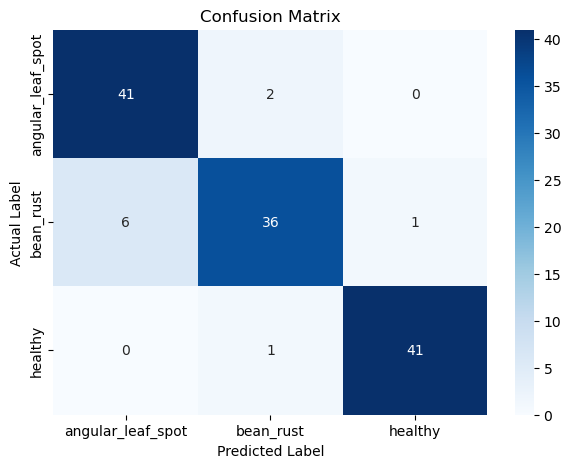

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Actual and predicted labels
y_true = test_generator.classes
y_pred = np.argmax(model.predict(test_generator), axis=1)

# Class names
class_names = list(test_generator.class_indices.keys())

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()


### Insight

The confusion matrix shows that the model correctly classifies most bean leaf images, with the strongest performance for the **Healthy** class. Most misclassifications occur between **Angular Leaf Spot** and **Bean Rust**.

### SAMPLE PREDICTION

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 498ms/step


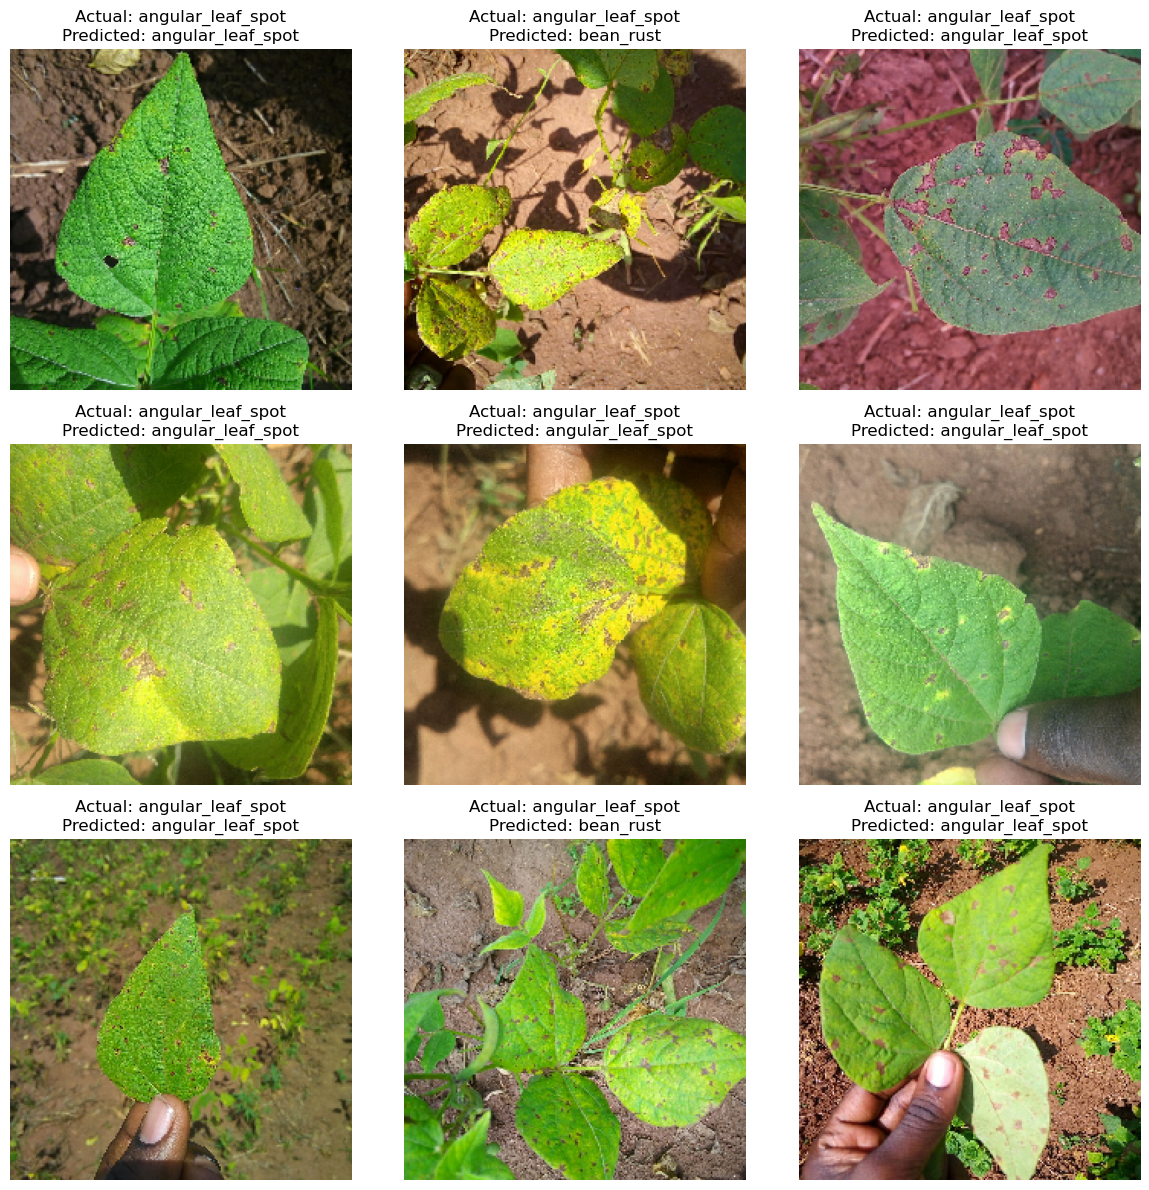

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Get one batch of test images
images, true_labels = next(test_generator)

# Predict
predictions = model.predict(images)
predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(true_labels, axis=1)

# Display 9 images
plt.figure(figsize=(12, 12))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    
    plt.imshow(images[i])
    
    actual = class_names[actual_labels[i]]
    predicted = class_names[predicted_labels[i]]
    
    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Insight

A sample of **9 unseen test images** was visualized along with their actual and predicted labels. The model correctly classified **7 out of 9 images**, demonstrating that it can recognize the bean leaf categories effectively on individual unseen examples.

The two incorrect predictions show that some visual similarities remain between the leaf disease classes, particularly between **Angular Leaf Spot and Bean Rust**.

### SAVING THE MODEL

In [30]:
model.save("bean_leaf_classifier_mobilenetv2.keras")

print("Model saved successfully.")

Model saved successfully.


### TRAIN ACCURACY AND LOSS GRAPHS

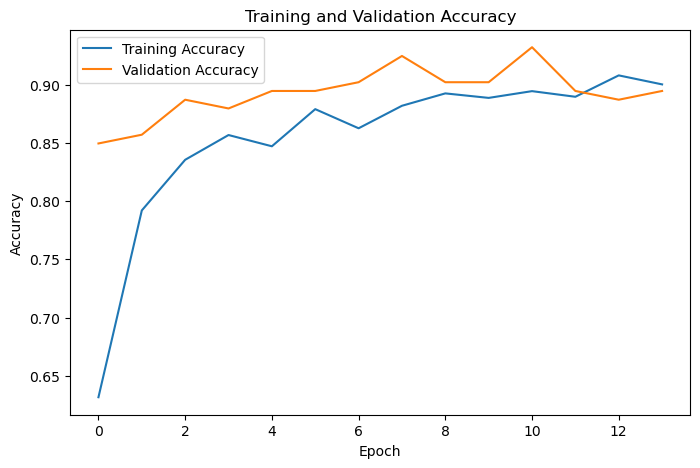

In [33]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

### Insight

The training and validation loss generally **decrease over the epochs**, indicating that the model is learning effectively. The **lowest validation loss is reached around Epoch 11**, after which validation loss increases, suggesting that further training may lead to overfitting.

The use of **EarlyStopping** therefore helps retain the model from its best validation point and improves generalization.

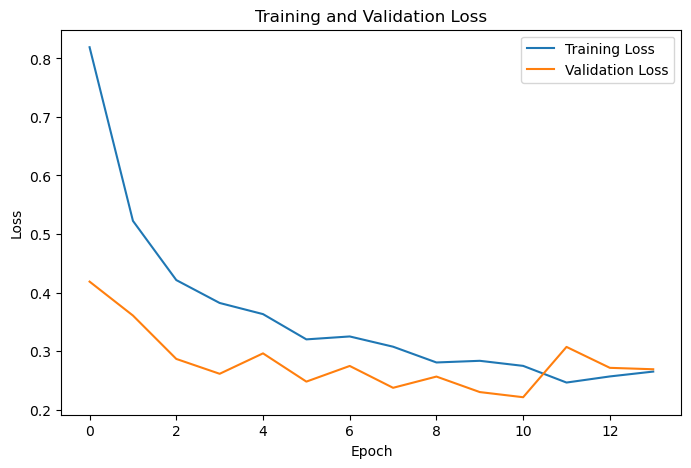

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

### Insight

The graph shows that both **training and validation loss decrease significantly during training**, indicating that the model is learning useful features. The validation loss reaches its lowest point around **Epoch 11**, after which it increases, indicating that further training may start to cause overfitting.

Therefore, **EarlyStopping** helps select the model weights from the best validation-loss point and improves generalization on unseen data.

# Project Conclusion Report

## 1. Project Overview

The objective of this project was to develop a deep learning model capable of classifying bean leaf images into three predefined categories:

1. **Angular Leaf Spot**
2. **Bean Rust**
3. **Healthy**

A transfer learning approach was used with **MobileNetV2**, a pretrained convolutional neural network trained on ImageNet. The pretrained network was used as a feature extractor, while custom classification layers were added to perform the three-class bean leaf classification task.

---

## 2. Dataset Summary

The dataset was organized into separate **training, validation, and testing** directories.

| Dataset | Number of Images |
|---|---:|
| Training | 1,034 |
| Validation | 133 |
| Testing | 128 |
| **Total** | **1,295** |

All images were resized to **224 × 224 pixels** before being provided to the model.

The three classes were encoded as:

- `angular_leaf_spot` → 0
- `bean_rust` → 1
- `healthy` → 2

---

## 3. Data Preprocessing and Augmentation

Training images were rescaled to the range **0–1** and augmented using:

- Rotation
- Width shifting
- Height shifting
- Zooming
- Horizontal flipping

Validation and test images were only rescaled and were **not augmented**. This ensured that validation and test performance represented the model's performance on images without artificially modifying the evaluation data.

The training generator used shuffling, while validation and test generators were kept unshuffled for consistent evaluation and correct matching of predictions with their actual labels.

---

## 4. Model Architecture

The final model was built using **MobileNetV2 with ImageNet pretrained weights**.

The architecture consisted of:

- Pretrained **MobileNetV2**
- Frozen pretrained convolutional layers
- **Global Average Pooling**
- **Dense layer with 128 neurons and ReLU activation**
- **Dropout of 0.5**
- **Softmax output layer with 3 neurons**

The pretrained MobileNetV2 layers were frozen so that their learned visual features could be reused without updating their weights during training.

The **Dropout rate of 0.5** was introduced to reduce overfitting and improve generalization.

---

## 5. Model Compilation

The model was compiled using:

- **Optimizer:** Adam
- **Loss Function:** Categorical Cross-Entropy
- **Evaluation Metric:** Accuracy

Categorical cross-entropy was selected because this is a **three-class classification problem with categorical labels**.

---

## 6. Training Strategy

The model was trained for a maximum of **20 epochs** with EarlyStopping.

EarlyStopping was configured as:

- Monitoring: `val_loss`
- Patience: `3`
- Restore best weights: `True`

The best validation performance was obtained around **Epoch 11**.

### Best Training Results

| Metric | Value |
|---|---:|
| Training Accuracy at Epoch 11 | **89.46%** |
| Validation Accuracy at Epoch 11 | **93.23%** |
| Validation Loss at Epoch 11 | **0.2211** |

After Epoch 11, the validation loss increased:

- Epoch 11: **0.2211**
- Epoch 12: **0.3071**
- Epoch 13: **0.2713**
- Epoch 14: **0.2689**

This indicated that further training was no longer improving validation performance. EarlyStopping therefore helped prevent unnecessary training and retained the best-performing model weights.

---

## 7. Final Test Performance

After the model was finalized, it was evaluated on the **128 completely unseen test images**.

### Final Test Scores

| Metric | Score |
|---|---:|
| **Test Loss** | **0.2327** |
| **Test Accuracy** | **92.19%** |

The model correctly classified approximately **92% of the unseen test images**, demonstrating strong generalization to images that were not used during training.

---

## 8. Confusion Matrix

The final confusion matrix was:

```text
[[41  2  0]
 [ 6 36  1]
 [ 0  1 41]]